# 15 Two-part model, 09:00 cutoff

Notebook 14: anomaly features fix the late-fold level but lose the within-day ranking gain; absolute features keep the ranking but pull the level down. A two-part model separates the two jobs.

`forecast = ref28 + L(D) + s(p)`, where

- **shape `s(p)`** is learned from the absolute weather and calendar features, on the within-day centred deviation `(price - ref28) - mean over the day of (price - ref28)`; its predictions are centred within each day, so it carries no level, only which periods are relatively dearer or cheaper than the reference suggests;
- **level `L(D)`** is a daily model: the day's mean deviation from `ref28`, regressed (Huber, alpha 10, standardised) on the day's mean anomaly features (demand, Elexon wind, embedded wind, embedded solar) and the weekend and bank-holiday flags. No level/history terms and no absolute weather levels.

The level part is constant within a day, so the ranking within a day comes only from `ref28` plus the shape part.

Pre-specified 2 x 2: shape model {Huber (alpha 30, splines as in 11), gradient boosting (as in 07, without history or margin inputs)} x level {none (`L = 0`), anomaly Huber}. All four reported, with V0 and V3 from notebook 14 for reference. Same 17 folds; all folds, folds 0-12 and 13-16.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
VAL = D9["day"].isin(val_days_all)
REF = "med28_same"
COMMON = D9[REF].notna() & D9["price"].notna()

D9["ydev"] = D9["price"] - D9[REF]
dm = D9[COMMON].groupby("day")["ydev"].agg(["mean", "count"])
D9["day_mean_ydev"] = D9["day"].map(dm["mean"])
D9["ydev_c"] = D9["ydev"] - D9["day_mean_ydev"]
print(int((VAL & COMMON).sum()), "scored rows;", "days with a daily target:", int((dm["count"] >= 40).sum()))

22847 scored rows; days with a daily target: 659


## 1. Daily table for the level part

One row per day: the mean deviation of the day's prices from `ref28` (target, only days with at least 40 valid periods), and the mean anomaly of each forecast over the day's periods (periods without a forecast are ignored in the mean).

In [2]:
ANOM = ["demand_anom", "wind_anom", "emb_wind_anom", "emb_solar_anom"]
daily = D9.groupby("day").agg(**{c: (c, "mean") for c in ANOM}, is_weekend=("is_weekend", "mean"), bank_holiday=("bank_holiday", "mean"))
daily["target"] = dm["mean"].where(dm["count"] >= 40)
print(daily.describe().round(1).T.to_string())
print("\ncorrelation of the daily level target with the daily anomalies:")
print(daily.corr()["target"].round(2).to_string())

                count   mean     std      min     25%    50%     75%      max
demand_anom     657.0 -129.6  2586.6  -7206.1 -1823.0  -82.4  1580.6   7876.8
wind_anom       657.0  -63.7  4553.0 -10639.1 -3167.5 -593.3  3095.8  12487.2
emb_wind_anom   657.0  -12.8  1163.2  -2358.5  -846.1 -204.0   761.9   4136.0
emb_solar_anom  657.0   69.1   692.1  -2304.2  -358.0   18.8   485.9   1989.5
is_weekend      674.0    0.3     0.5      0.0     0.0    0.0     1.0      1.0
bank_holiday    674.0    0.0     0.1      0.0     0.0    0.0     0.0      1.0
target          659.0   -1.7    34.4   -102.6   -13.5    1.9    12.7    603.1

correlation of the daily level target with the daily anomalies:
demand_anom       0.45
wind_anom        -0.44
emb_wind_anom    -0.47
emb_solar_anom    0.04
is_weekend       -0.20
bank_holiday     -0.03
target            1.00


## 2. Models

In [3]:
ABS = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
OTH = ["bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
GBM_COLS = ["hour_frac", "weekday", "is_weekend"] + OTH + ABS + ["wind_total_mw", "demand_age_h", "wind_age_h", "emb_age_h",
            "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"]
HUB_COLS = ABS + ["hour_frac"] + OTH + ["weekday"]

def shape_model(kind):
    if kind == "huber":
        pre = ColumnTransformer([
            ("spl", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(n_knots=6, degree=3, extrapolation="linear"), StandardScaler()), ABS),
            ("hour", SplineTransformer(knots=np.linspace(0, 24, 13).reshape(-1, 1), degree=3, extrapolation="periodic"), ["hour_frac"]),
            ("lin", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), OTH),
            ("wd", OneHotEncoder(handle_unknown="ignore"), ["weekday"])])
        return Pipeline([("pre", pre), ("est", HuberRegressor(alpha=30, epsilon=1.35, max_iter=300))]), HUB_COLS
    m = HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                      min_samples_leaf=100, l2_regularization=1.0, early_stopping=False, random_state=0)
    return m, GBM_COLS

LVL_COLS = ANOM + ["is_weekend", "bank_holiday"]
def level_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), HuberRegressor(alpha=10, epsilon=1.35, max_iter=300))

def run_cv(shape_kind, level):
    pred = pd.Series(np.nan, index=D9.index)
    shape_part = pd.Series(np.nan, index=D9.index)
    level_pred = pd.Series(np.nan, index=daily.index)
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & COMMON]
        va = D9[D9["day"].isin(f["val_days"])]
        m, cols = shape_model(shape_kind)
        m.fit(tr[cols], tr["ydev_c"])
        s = pd.Series(m.predict(va[cols]), index=va.index)
        s = s - s.groupby(va["day"]).transform("mean")                    # centre within each day
        shape_part.loc[va.index] = s
        if level == "anomaly":
            dtr = daily.loc[daily.index.isin(f["train_days"]) & daily["target"].notna()]
            lm = level_model().fit(dtr[LVL_COLS], dtr["target"])
            dva = daily.loc[daily.index.isin(f["val_days"])]
            lp = pd.Series(lm.predict(dva[LVL_COLS]), index=dva.index)
        else:
            lp = pd.Series(0.0, index=daily.index[daily.index.isin(f["val_days"])])
        level_pred.loc[lp.index] = lp
        pred.loc[va.index] = va[REF] + va["day"].map(lp) + s
    return pred, level_pred

def fold_table(pred):
    rows = []
    for f in folds:
        d = D9[D9["day"].isin(f["val_days"]) & COMMON].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = fold_table(D9[REF])
late_days = pd.DatetimeIndex(np.concatenate([folds[k]["val_days"].values for k in range(13, 17)]))
LATE = D9["day"].isin(late_days) & COMMON
print("ready")

ready


## 3. Run

Plus V0 (absolute weather + history, Huber and GBM) and V3 (anomaly, no history) from notebook 14 for reference. `pred dev late` and `actual dev late` are the mean predicted and actual deviation from `ref28` over folds 13-16.

In [4]:
RES, FT, PRED, LV = {}, {}, {}, {}
t0 = time.time()
for sk in ["huber", "gbm"]:
    for lv in ["none", "anomaly"]:
        key = f"two-part: {sk} shape, level {lv}"
        PRED[key], LV[key] = run_cv(sk, lv)
        FT[key] = fold_table(PRED[key])
        print(f"{key:40s} {time.time() - t0:4.0f}s")
old = pd.read_parquet("outputs/cv_preds_anomaly_0900.parquet")
OLD = D9[["period_start"]].merge(old, on="period_start", how="left").drop(columns=["day", "price", REF])
for c in ["huber V0 absolute + history", "huber V3 anomaly, no history", "gbm V0 absolute + history", "gbm V3 anomaly, no history"]:
    s = pd.Series(OLD[c].to_numpy(), index=D9.index); PRED["14: " + c] = s; FT["14: " + c] = fold_table(s)

def row(key):
    ft = FT[key]; d = {m: ft[m] - BASE[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
    return {"dMAE all": d["MAE"].mean(), "dMAE 0-12": d["MAE"].loc[:12].mean(), "dMAE late": d["MAE"].loc[13:].mean(),
            "dRMSE all": d["RMSE"].mean(), "dRMSE late": d["RMSE"].loc[13:].mean(),
            "dHitTop all": d["hit_top8"].mean(), "dHitTop late": d["hit_top8"].loc[13:].mean(),
            "dHitBot all": d["hit_bot8"].mean(), "dHitBot late": d["hit_bot8"].loc[13:].mean(),
            "bias late": ft["bias"].loc[13:].mean(), "bias f16": ft["bias"].loc[16],
            "pred dev late": (PRED[key] - D9[REF])[LATE].mean(), "actual dev late": D9.loc[LATE, "ydev"].mean()}
R = pd.DataFrame({k: row(k) for k in FT}).T
print(R.round(2).to_string())
P = pd.DataFrame({k: v for k, v in PRED.items() if k.startswith("two-part")})
for c in ["day", "period_start", "price", REF]:
    P[c] = D9[c]
P.loc[VAL].to_parquet("outputs/cv_preds_twopart_0900.parquet", index=False)

two-part: huber shape, level none           6s


two-part: huber shape, level anomaly       11s


two-part: gbm shape, level none            23s


two-part: gbm shape, level anomaly         36s


                                      dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop all  dHitTop late  dHitBot all  dHitBot late  bias late  bias f16  pred dev late  actual dev late
two-part: huber shape, level none        -0.06      -0.08      -0.00      -0.29       -0.39         0.00          0.01         0.02         -0.01      -0.68     -6.75           0.00             0.68
two-part: huber shape, level anomaly     -1.45      -1.55      -1.13      -3.24       -2.85         0.00          0.01         0.02         -0.01      -2.18     -8.44          -1.51             0.68
two-part: gbm shape, level none          -0.11      -0.06      -0.26      -0.51       -1.01        -0.01         -0.00         0.02         -0.00      -0.68     -6.75          -0.00             0.68
two-part: gbm shape, level anomaly       -1.68      -1.71      -1.57      -3.48       -3.50        -0.01         -0.00         0.02         -0.00      -2.18     -8.44          -1.51             0.68
14: h

## 4. Does the level part work on its own?

Out-of-sample daily level model: on the validation days, the correlation between the predicted and actual daily mean deviation, and the RMSE of the daily mean deviation when predicting `L` against when predicting zero (the reference alone). Over all validation days and over the last four folds.

                all validation days  folds 13-16
days                         476.00       112.00
corr                           0.67         0.68
RMSE with L                   19.20        19.43
RMSE with zero                25.11        24.63
mean target                   -1.89         0.68
mean pred                     -2.57        -1.51


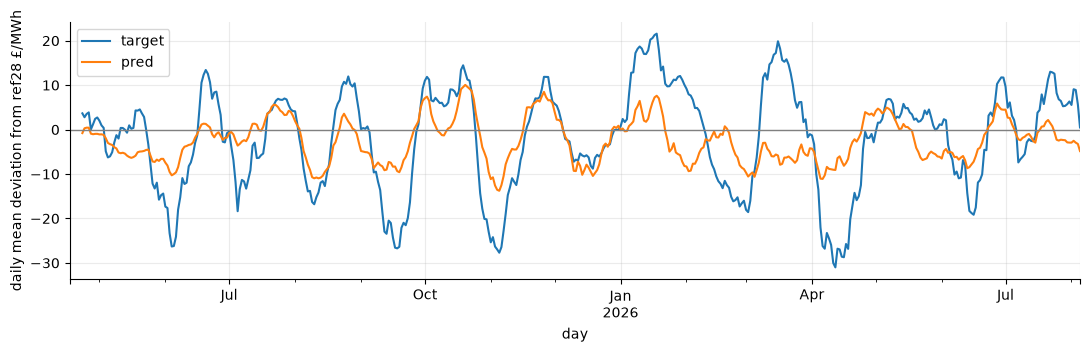

In [5]:
lp = LV["two-part: huber shape, level anomaly"]
cmp = daily[["target"]].join(lp.rename("pred")).dropna()
cmp = cmp[cmp.index.isin(val_days_all)]
def lvl_stats(c):
    return {"days": len(c), "corr": c["target"].corr(c["pred"]),
            "RMSE with L": np.sqrt(((c["target"] - c["pred"]) ** 2).mean()), "RMSE with zero": np.sqrt((c["target"] ** 2).mean()),
            "mean target": c["target"].mean(), "mean pred": c["pred"].mean()}
print(pd.DataFrame({"all validation days": lvl_stats(cmp), "folds 13-16": lvl_stats(cmp[cmp.index.isin(late_days)])}).round(2).to_string())
fig, ax = plt.subplots(figsize=(11, 3.5))
cmp[["target", "pred"]].rolling(14, min_periods=7).mean().plot(ax=ax)
ax.set_ylabel("daily mean deviation from ref28 \u00a3/MWh"); ax.axhline(0, color="grey", lw=1)
plt.tight_layout(); plt.show()

## 5. Paired against the best single-part references

Mean difference over the 17 folds (+/- standard error) of the two-part models against V0 and V3 of the same shape family, and over folds 13-16.

In [6]:
rows = {}
for sk in ["huber", "gbm"]:
    for lv in ["none", "anomaly"]:
        key = f"two-part: {sk} shape, level {lv}"
        for ref in [f"14: {sk} V0 absolute + history", f"14: {sk} V3 anomaly, no history"]:
            r = {}
            for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
                d = FT[key][m] - FT[ref][m]
                r[f"{m} all"] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(17):.3f}"; r[f"{m} late"] = f"{d.loc[13:].mean():+.3f}"
            rows[f"{key}  vs  {ref[4:]}"] = r
print(pd.DataFrame(rows).T.to_string())

                                                                                 MAE all MAE late          RMSE all RMSE late      hit_top8 all hit_top8 late      hit_bot8 all hit_bot8 late
two-part: huber shape, level none  vs  huber V0 absolute + history      +1.842 +/- 0.742   +0.233  +3.837 +/- 0.981    +1.427  -0.027 +/- 0.006        -0.001  -0.026 +/- 0.009        -0.012
two-part: huber shape, level none  vs  huber V3 anomaly, no history     +1.744 +/- 0.650   +1.288  +3.407 +/- 0.865    +2.494  -0.002 +/- 0.004        +0.006  -0.006 +/- 0.009        -0.007
two-part: huber shape, level anomaly  vs  huber V0 absolute + history   +0.451 +/- 0.447   -0.899  +0.885 +/- 0.554    -1.025  -0.027 +/- 0.006        -0.001  -0.026 +/- 0.009        -0.012
two-part: huber shape, level anomaly  vs  huber V3 anomaly, no history  +0.354 +/- 0.303   +0.155  +0.455 +/- 0.386    +0.043  -0.002 +/- 0.004        +0.006  -0.006 +/- 0.009        -0.007
two-part: gbm shape, level none  vs  gbm V0 absolu

## 6. V0 ordering with the anomaly level

In the two-part models above, the shape part adds little (`level none` rows are close to the baseline), yet V0 had the ranking gain. So the ranking in V0 comes from something the two-part shape model does not have (V0 uses the history inputs together with the weather). A direct test of whether ranking and level are separable: keep V0's predictions within each day (centred, so its ordering of the day's periods is unchanged) and replace the day's level by the anomaly level model `L(D)` from above: `forecast = ref28 + L(D) + [(V0 - ref28) - day mean of (V0 - ref28)]`. Specified in advance for both families.

In [7]:
rows = {}
lv = LV["two-part: huber shape, level anomaly"]
for fam in ["huber", "gbm"]:
    p0 = PRED[f"14: {fam} V0 absolute + history"]
    dev0 = p0 - D9[REF]
    dev0_c = dev0 - dev0.groupby(D9["day"]).transform("mean")
    key = f"V0 {fam} ordering + anomaly level"
    PRED[key] = D9[REF] + D9["day"].map(lv) + dev0_c
    FT[key] = fold_table(PRED[key])
    rows[key] = row(key)
    rows[f"14: {fam} V0 absolute + history"] = row(f"14: {fam} V0 absolute + history")
print(pd.DataFrame(rows).T.round(2).to_string())

print()
print("paired, mean per-fold difference +/- standard error over 17 folds (late = mean over folds 13-16):")
pr = {}
for fam in ["huber", "gbm"]:
    key = f"V0 {fam} ordering + anomaly level"
    for lab, ref in [("baseline", BASE), (f"V0 {fam}", FT[f"14: {fam} V0 absolute + history"])]:
        r = {}
        for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
            d = FT[key][m] - ref[m]
            r[f"{m} all"] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(17):.3f}"; r[f"{m} late"] = f"{d.loc[13:].mean():+.3f}"
        r["folds MAE better"] = int(((FT[key]["MAE"] - ref["MAE"]) < 0).sum())
        pr[f"{key}  vs  {lab}"] = r
print(pd.DataFrame(pr).T.to_string())

                                   dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop all  dHitTop late  dHitBot all  dHitBot late  bias late  bias f16  pred dev late  actual dev late
V0 huber ordering + anomaly level     -2.06      -2.24      -1.50      -4.30       -3.29         0.03          0.01         0.05          0.00      -2.18     -8.44          -1.51             0.68
14: huber V0 absolute + history       -1.90      -2.42      -0.24      -4.12       -1.82         0.03          0.01         0.05          0.00     -11.77    -15.35         -11.10             0.68
V0 gbm ordering + anomaly level       -2.04      -2.18      -1.61      -4.06       -3.48         0.02          0.02         0.04          0.01      -2.18     -8.44          -1.51             0.68
14: gbm V0 absolute + history         -1.65      -2.07      -0.28      -3.26       -1.42         0.02          0.02         0.04          0.01     -14.48    -19.08         -13.80             0.68

paired, mean per-fo

## Findings (09:00, 17 folds, differences to the 28-day median baseline; the four two-part models and the recombination were specified before running)

- **The within-day shape part adds almost nothing.** With no level adjustment (`level none`) the two-part models are about the baseline: MAE -0.06 (Huber) and -0.11 (GBM), hit rates +0.01/+0.02 or less. The weather inputs, used in this form, do not explain which periods of a day are relatively dearer or cheaper than the 28-day profile suggests.
- **The daily level part carries the gain, and it works out of sample.** The daily model (mean anomalies of demand, wind and solar; Huber, alpha 10) correlates 0.67 with the actual daily mean deviation from `ref28` on the validation days (0.68 on folds 13-16) and cuts the RMSE of the daily deviation from 25.1 (reference alone) to 19.2 (19.4 against 24.6 in the late folds), i.e. about 40% of its variance. With it, the two-part models reach MAE -1.45 (Huber) and -1.68 (GBM) over all folds, -1.13 and -1.57 over folds 13-16, late mean error -2.2 (fold 16: -8.4) and RMSE -3.2/-3.5. Their hit-rate gains are small (+0.01/+0.02), the same as V3 in notebook 14: they do not reproduce V0's ranking gain.
- **V0's ranking comes from the history inputs working together with the weather, not from weather alone.** The shape models here have the weather and calendar but no history inputs and do not recover it (paired against Huber V0: top-8 hit -0.027 +/- 0.006, bottom-8 -0.026 +/- 0.009). Notebook 13 showed the same: removing `history` from the full model dropped the hit-rate gain from +0.03/+0.05 to +0.01/+0.02. Why the combination ranks better is not explained here.
- **Keeping V0's ordering and swapping in the anomaly level gives both** (section 6, `V0 ... ordering + anomaly level`): Huber MAE -2.06 over all folds (V0 -1.90; V3 -1.81) and -1.50 over folds 13-16 (V0 -0.24); RMSE -4.30 and -3.29 (V0 -4.12 and -1.82); the within-day hit-rate gains are unchanged (+0.03/+0.05) because adding a per-day constant does not change the ordering within a day; mean error in folds 13-16 -2.2 (V0 -11.8) and in fold 16 -8.4 (V0 -15.4). GBM: MAE -2.04 and -1.61 (V0 -1.65 and -0.28), hit +0.02/+0.04. This is the best result so far on all of the metrics together.
- **Paired statistics for the recombination** (mean per-fold difference +/- standard error over 17 folds): against the baseline, Huber version MAE -2.06 +/- 0.57 (better in 14 of 17 folds), RMSE -4.30 +/- 0.75, top-8 hit +0.032 +/- 0.006, bottom-8 +0.049 +/- 0.014; GBM version MAE -2.04 +/- 0.62 (14 of 17), RMSE -4.06 +/- 0.74, hit +0.023 +/- 0.004 / +0.040 +/- 0.013. Against V0 of the same family the all-fold MAE difference is small (-0.16 +/- 0.36 Huber, -0.40 +/- 0.34 GBM); the improvement is in the late folds (-1.3 and -1.3 MAE, -1.5 and -2.1 RMSE). Note these standard errors treat the 17 adjacent folds as independent.
- **Caveats.** (1) The recombination was designed after seeing the results of notebooks 13-15 on these same folds, so its numbers are optimistic to some degree even though no parameters were tuned on them; the hold-out is the first test free of this. (2) The late-fold gain is based on four folds. (3) The level model has few effective inputs (four anomalies and two flags) and about 480-640 training days per fold. (4) The level model's mean prediction in the late folds is -1.5 against an actual +0.7, so some under-forecast remains, and the fold-16 mean error is still -8.4. (5) Quantile forecasts, the 07:00 cutoff, nested feature selection and seed checks of the new parts have not been done.
